# Customer Feedback Analysis & Automated Response
### Imarticus Data Science Internship — Assessment (Python Foundations & Gen AI)

**Problem:** A retail company gets thousands of reviews every week. Today the support team reads all of them by hand, picks out the urgent negative ones, and writes an apology email for each one.

**Objective:** Build a Python pipeline that:
1. **Data wrangling.** Load the reviews with Pandas, handle missing values, and clean the text.
2. **Rule-based filtering and insights.** Isolate *Critical* reviews **without Machine Learning** and find the most common complaint keywords using `collections.Counter`.
3. **Automated outreach (Gen AI).** Pick the 3 most critical, detailed reviews and have an LLM, acting as a Customer Support Agent, draft a short, personalised, empathetic apology email for each one.

**Dataset:** [Women's E-Commerce Clothing Reviews (Kaggle)](https://www.kaggle.com/datasets/nicapotato/womens-ecommerce-clothing-reviews). It has 23,486 reviews, each with review text and a 1–5 star rating.

---

## 0. Setup & Imports

In [1]:
import os
import re
import html
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Display settings
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

# Chart style: thin marks, light grid, muted axes
BLUE, CRITICAL_RED, GREY, MUTED = "#2a78d6", "#d03b3b", "#b9b7b0", "#898781"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": "#52514e",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10,
})

DATA_PATH = "Womens Clothing E-Commerce Reviews.csv"
print("Libraries loaded. pandas", pd.__version__)

Libraries loaded. pandas 3.0.6


---
## Task 1 — Data Wrangling (Python & Pandas)

### 1.1 Load the data

In [2]:
# The first column in the CSV is an unnamed row index, so we use it as the index.
df_raw = pd.read_csv(DATA_PATH, index_col=0)

print(f"Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns\n")
df_raw.info()

Shape: 23,486 rows x 10 columns

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Clothing ID              23486 non-null  int64
 1   Age                      23486 non-null  int64
 2   Title                    19676 non-null  str  
 3   Review Text              22641 non-null  str  
 4   Rating                   23486 non-null  int64
 5   Recommended IND          23486 non-null  int64
 6   Positive Feedback Count  23486 non-null  int64
 7   Division Name            23472 non-null  str  
 8   Department Name          23472 non-null  str  
 9   Class Name               23472 non-null  str  
dtypes: int64(5), str(5)
memory usage: 1.8 MB


In [3]:
df_raw.head()

,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have orde...",5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my u...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great comp...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings...,5,1,6,General,Tops,Blouses


### 1.2 Inspect missing values, duplicates and the rating distribution

In [4]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_%": (df_raw.isna().mean() * 100).round(2),
})
display(missing[missing.missing_count > 0])

print("Fully duplicated rows        :", df_raw.duplicated().sum())
print("Duplicate non-empty reviews  :", df_raw["Review Text"].dropna().duplicated().sum())
print("\nRating distribution:")
print(df_raw["Rating"].value_counts().sort_index())

,missing_count,missing_%
Title,3810,16.22
Review Text,845,3.60
Division Name,14,0.06
Department Name,14,0.06
Class Name,14,0.06


Fully duplicated rows        : 21
Duplicate non-empty reviews  : 7

Rating distribution:
Rating
1      842
2     1565
3     2871
4     5077
5    13131
Name: count, dtype: int64


**Observations**
- `Review Text` is missing for **845** rows. We need text for keyword analysis and email generation, and a rating alone can't be answered personally, so we **drop** these rows.
- `Title` is missing for **3,810** rows. It is optional, so we **fill it with an empty string** and keep the review.
- `Division / Department / Class Name` are missing for **14** rows. We **fill them with `"Unknown"`** so the reviews stay in the data.
- There are a few exact duplicate rows, which we **remove** so they aren't counted twice.

### 1.3 Handle missing values & duplicates

In [5]:
df = df_raw.copy()
rows_before = len(df)

# 1) Drop rows without review text (nothing to analyse or respond to)
df = df.dropna(subset=["Review Text"])

# 2) Title is optional: fill with an empty string
df["Title"] = df["Title"].fillna("")

# 3) Categorical product info: fill with an explicit 'Unknown' label
for col in ["Division Name", "Department Name", "Class Name"]:
    df[col] = df[col].fillna("Unknown")

# 4) Remove exact duplicate reviews (same item, same text, same rating)
df = df.drop_duplicates(subset=["Clothing ID", "Review Text", "Rating"])

# 5) Fix a spelling inconsistency in the source data ("Initmates")
df["Division Name"] = df["Division Name"].replace({"Initmates": "Intimates"})

# 6) Make sure the numeric columns have the right types
df["Rating"] = df["Rating"].astype(int)
df["Recommended IND"] = df["Recommended IND"].astype(int)

df = df.reset_index(drop=True)
print(f"Rows before: {rows_before:,}  ->  rows after: {len(df):,}  (removed {rows_before - len(df):,})")
print("Remaining missing values:", int(df.isna().sum().sum()))

Rows before: 23,486  ->  rows after: 22,639  (removed 847)
Remaining missing values: 0


### 1.4 Clean the text

We keep **two versions** of each review:
| Column | Used for | What it looks like |
|---|---|---|
| `Review Text` (original) | Sending to the LLM, since the model understands natural punctuation and casing better | `"The fabric RIPPED after 1 wash!!"` |
| `clean_text` (normalised) | Counting keywords, where `"Ripped!"` and `"ripped"` must count as the same word | `"the fabric ripped after wash"` |

**Cleaning steps in `clean_text()`:**
1. Decode HTML entities (`&amp;` → `&`) and normalise unicode (curly quotes and accents become plain ASCII).
2. **Standardise case:** convert everything to lowercase.
3. Remove apostrophes so contractions stay one token (`didn't` → `didnt`).
4. **Remove special characters, digits and punctuation:** keep only letters a–z.
5. Collapse repeated whitespace.

In [6]:
def clean_text(text: str) -> str:
    # Normalise a raw review into lowercase, letters-only text.
    if not isinstance(text, str):
        return ""
    text = html.unescape(text)                                   # &amp; -> &
    text = unicodedata.normalize("NFKD", text)                   # curly quotes / accents -> base chars
    text = text.encode("ascii", "ignore").decode("ascii")
    text = text.lower()                                          # standardise case
    text = re.sub(r"['`]", "", text)                             # didn't -> didnt
    text = re.sub(r"[^a-z\s]", " ", text)                        # remove special chars, digits, punctuation
    text = re.sub(r"\s+", " ", text).strip()                     # collapse whitespace
    return text


# Clean both the title and the body, then combine them for keyword analysis
df["clean_title"] = df["Title"].apply(clean_text)
df["clean_review"] = df["Review Text"].apply(clean_text)
df["clean_text"] = (df["clean_title"] + " " + df["clean_review"]).str.strip()

# Simple text features used later by the rules
df["word_count"] = df["clean_review"].str.split().str.len()

# Before / after comparison
sample = df.loc[df["Review Text"].str.contains(r"[!?&\d]", regex=True)].head(3)
for _, r in sample.iterrows():
    print("BEFORE:", r["Review Text"][:150])
    print("AFTER :", r["clean_review"][:150], "\n")

BEFORE: Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i b
AFTER : love this dress its sooo pretty i happened to find it in a store and im glad i did bc i never would have ordered it online bc its petite i bought a pe 

BEFORE: I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be 
AFTER : i had such high hopes for this dress and really wanted it to work for me i initially ordered the petite small my usual size but i found this to be out 

BEFORE: I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great compliments!
AFTER : i love love love this jumpsuit its fun flirty and fabulous every time i wear it i get nothing but great compliments 



In [7]:
df[["Title", "Review Text", "Rating", "clean_text", "word_count"]].head()

,Title,Review Text,Rating,clean_text,word_count
0,,Absolutely wonderful - silky and sexy and comfortable,4,absolutely wonderful silky and sexy and comfortable,7
1,,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have orde...",5,love this dress its sooo pretty i happened to find it in a store and im glad i did bc i never would have ordered it ...,61
2,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my u...,3,some major design flaws i had such high hopes for this dress and really wanted it to work for me i initially ordered...,97
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great comp...",5,my favorite buy i love love love this jumpsuit its fun flirty and fabulous every time i wear it i get nothing but gr...,22
4,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings...,5,flattering shirt this shirt is very flattering to all due to the adjustable front tie it is the perfect length to we...,36


---
## Task 2 — Rule-Based Filtering & Insights (no Machine Learning)

### 2.1 Define and isolate "Critical" reviews

**Rule:** a review is **Critical** if `Rating <= 2` (1 or 2 stars).

This is a plain boolean mask in Pandas. No model is trained.

In [8]:
CRITICAL_MAX_RATING = 2

def is_critical(rating: int) -> bool:
    # Rule: 1- and 2-star reviews are Critical.
    return rating <= CRITICAL_MAX_RATING

df["is_critical"] = df["Rating"].apply(is_critical)
critical = df[df["is_critical"]].copy()

n_total, n_crit = len(df), len(critical)
print(f"Critical reviews: {n_crit:,} of {n_total:,} ({n_crit / n_total:.1%})")
print(critical["Rating"].value_counts().sort_index().rename("count"))

Critical reviews: 2,369 of 22,639 (10.5%)
Rating
1     821
2    1548
Name: count, dtype: int64


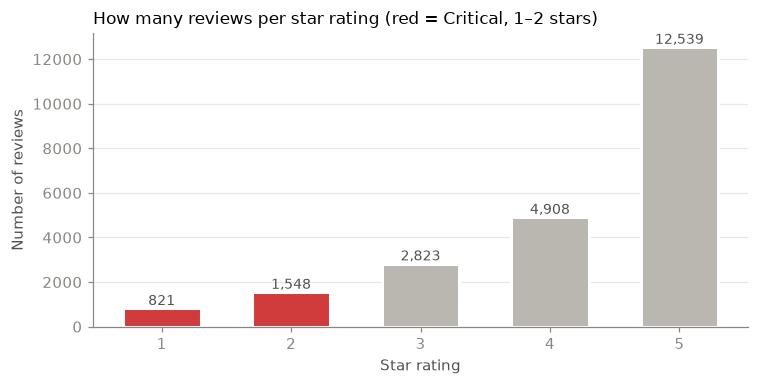

In [9]:
# Chart: rating distribution, with the Critical bars (1-2 stars) highlighted
counts = df["Rating"].value_counts().sort_index()
colors = [CRITICAL_RED if is_critical(r) else GREY for r in counts.index]

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(counts.index.astype(str), counts.values, color=colors, width=0.6, edgecolor="white", linewidth=2)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 150, f"{v:,}", ha="center", fontsize=9, color="#52514e")
ax.set_title("How many reviews per star rating (red = Critical, 1–2 stars)", loc="left", fontsize=11)
ax.set_xlabel("Star rating"); ax.set_ylabel("Number of reviews")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 2.2 Where do Critical reviews come from?
Compare the **share** of Critical reviews in each department. Raw counts would just follow how many reviews each department gets.

In [10]:
dept = (df.groupby("Department Name")
          .agg(total_reviews=("Rating", "size"),
               critical_reviews=("is_critical", "sum"),
               avg_rating=("Rating", "mean"))
          .assign(critical_rate=lambda d: (d.critical_reviews / d.total_reviews * 100).round(1),
                  avg_rating=lambda d: d.avg_rating.round(2))
          .sort_values("critical_rate", ascending=False))
display(dept)

# Classes with at least 100 reviews, ranked by critical rate
cls = (df.groupby("Class Name")
         .agg(total_reviews=("Rating", "size"), critical_reviews=("is_critical", "sum"))
         .query("total_reviews >= 100")
         .assign(critical_rate=lambda d: (d.critical_reviews / d.total_reviews * 100).round(1))
         .sort_values("critical_rate", ascending=False))
print("\nTop 5 product classes by critical rate (min 100 reviews):")
display(cls.head(5))

,total_reviews,critical_reviews,avg_rating,critical_rate
Department Name,,,,
Trend,118,21,3.84,17.8
Dresses,6144,680,4.14,11.1
Tops,10048,1096,4.16,10.9
Jackets,1002,108,4.25,10.8
Intimate,1653,147,4.27,8.9
Bottoms,3661,317,4.28,8.7
Unknown,13,0,5.00,0.0



Top 5 product classes by critical rate (min 100 reviews):


,total_reviews,critical_reviews,critical_rate
Class Name,,,
Trend,118,21,17.8
Blouses,2983,343,11.5
Swim,332,38,11.4
Outerwear,319,36,11.3
Dresses,6144,680,11.1


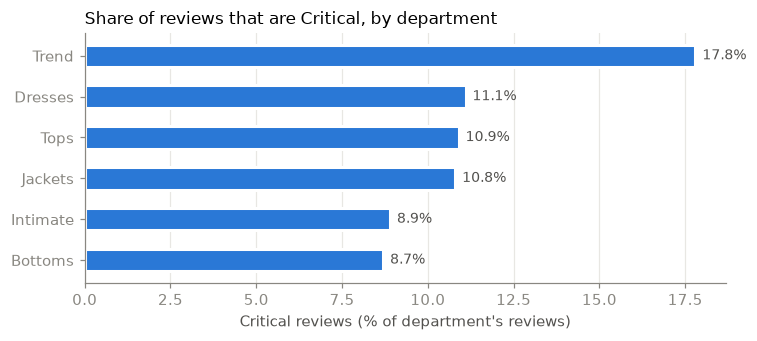

In [11]:
d = dept.drop(index="Unknown", errors="ignore").sort_values("critical_rate")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(d.index, d["critical_rate"], color=BLUE, height=0.55, edgecolor="white", linewidth=2)
for y, v in enumerate(d["critical_rate"]):
    ax.text(v + 0.2, y, f"{v}%", va="center", fontsize=9, color="#52514e")
ax.set_title("Share of reviews that are Critical, by department", loc="left", fontsize=11)
ax.set_xlabel("Critical reviews (% of department's reviews)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 2.3 Most common complaint keywords (`collections.Counter`)

A raw word count of negative reviews is dominated by words like *"the"*, *"dress"* and *"love"*. To surface the real **complaints**, the function `top_complaint_keywords()`:

1. **Tokenises** the cleaned text with `str.split()`.
2. **Removes stop words.** We use a hand-written set of English filler words plus words that are neutral in this domain (*dress, top, wear, ordered…*).
3. **Counts** the remaining words (and two-word phrases such as *"poor quality"*) with `Counter`.
4. Optionally ranks words by **lift**, which is how much more often a word appears in Critical reviews than in positive (4–5★) ones. This filters out words that are frequent everywhere (like *"size"*) and keeps words that signal a complaint (like *"returned"* or *"cheap"*).

In [12]:
# Hand-written stop words (no external NLP library needed)
STOP_WORDS = set('''
a about above after again against all am an and any are arent as at be because been before being below between both but by
can cant could couldnt did didnt do does doesnt doing dont down during each few for from further had hadnt has hasnt have
havent having he hed hes her here heres hers herself him himself his how hows i id ill im ive if in into is isnt it its
itself lets me more most mustnt my myself no nor not of off on once only or other ought our ours ourselves out over own
same shant she shed shell shes should shouldnt so some such than that thats the their theirs them themselves then there
theres these they theyd theyll theyre theyve this those through to too under until up very was wasnt we wed well were
weve werent what whats when whens where wheres which while who whos whom why whys with wont would wouldnt you youd youll
youre youve your yours yourself yourselves also just get got really one even much bit though will still way see
like dont im ive could would know think thought go going went make made say said us since back first want wanted lot
little many something thing things way yet however overall maybe probably sure else every
dress top shirt sweater jacket skirt pants jeans blouse item piece product retailer store online order ordered
wear wearing wore buy bought purchase purchased try tried trying color colors fabric material size sizes look looked
looks looking fit fits fitting
'''.split())


def tokenize(text: str) -> list[str]:
    # Split cleaned text into words, dropping stop words and very short tokens.
    return [w for w in text.split() if w not in STOP_WORDS and len(w) > 2]


def bigrams(tokens: list[str]) -> list[str]:
    # Adjacent word pairs, e.g. ['poor', 'quality'] -> 'poor quality'.
    return [f"{a} {b}" for a, b in zip(tokens, tokens[1:])]


def top_complaint_keywords(texts, n=15, ngram=1, baseline_texts=None, min_count=30):
    # Return the n most common complaint keywords in `texts`.
    # ngram=1 gives single words, ngram=2 gives two-word phrases.
    # With baseline_texts set, words are ranked by lift (how much more frequent they are
    # in `texts` than in the baseline) instead of by raw count.
    def count(series):
        c = Counter()
        for t in series:
            toks = tokenize(t)
            # Count each term at most once per review: "how many reviews mention X"
            c.update(set(toks if ngram == 1 else bigrams(toks)))
        return c

    crit_counts = count(texts)
    if baseline_texts is None:
        return pd.DataFrame(crit_counts.most_common(n), columns=["keyword", "reviews_mentioning"])

    base_counts = count(baseline_texts)
    n_crit, n_base = len(texts), len(baseline_texts)
    rows = []
    for word, c in crit_counts.items():
        if c < min_count:
            continue
        crit_rate = c / n_crit
        base_rate = (base_counts.get(word, 0) + 1) / n_base        # +1 smoothing avoids divide-by-zero
        rows.append((word, c, round(crit_rate * 100, 1), round(crit_rate / base_rate, 1)))
    out = pd.DataFrame(rows, columns=["keyword", "reviews_mentioning", "%_of_critical", "lift_vs_positive"])
    return out.sort_values(["lift_vs_positive", "reviews_mentioning"], ascending=False).head(n).reset_index(drop=True)


positive_texts = df.loc[df["Rating"] >= 4, "clean_text"]
crit_texts = critical["clean_text"]

#### (a) Most frequent words in Critical reviews (raw `Counter.most_common`)

In [13]:
top_words = top_complaint_keywords(crit_texts, n=20)
top_words

,keyword,reviews_mentioning
0,love,447
1,small,431
2,quality,362
3,cute,328
4,disappointed,303
5,great,297
6,large,282
7,flattering,248
8,big,244
9,work,243


> **Note:** the raw counts include words like *love*, *cute* and *great*. Unhappy customers often write *"I **wanted to love** this"* or *"the colour is **cute** but…"*. Raw frequency alone is therefore misleading, which is why we also look at **phrases** in (b) and **lift** in (c).

#### (b) Most frequent two-word complaint phrases

In [14]:
top_phrases = top_complaint_keywords(crit_texts, n=15, ngram=2)
top_phrases

,keyword,reviews_mentioning
0,poor quality,74
1,runs small,53
2,runs large,52
3,high hopes,46
4,arm holes,36
5,runs big,29
6,good quality,27
7,body type,26
8,small medium,25
9,read reviews,23


#### (c) Distinctive complaint keywords (ranked by lift vs. positive reviews)
`lift_vs_positive = 6` means the word is **6× more common** in Critical reviews than in 4–5★ reviews.

In [15]:
distinctive = top_complaint_keywords(crit_texts, n=20, baseline_texts=positive_texts, min_count=30)
distinctive

,keyword,reviews_mentioning,%_of_critical,lift_vs_positive
0,poorly,43,1.8,45.2
1,horrible,47,2.0,43.3
2,awful,63,2.7,38.7
3,poor,130,5.5,38.3
4,disappointing,106,4.5,28.9
5,disappointment,54,2.3,23.4
6,terrible,71,3.0,19.4
7,shame,31,1.3,17.6
8,unflattering,172,7.3,16.5
9,cheap,161,6.8,15.8


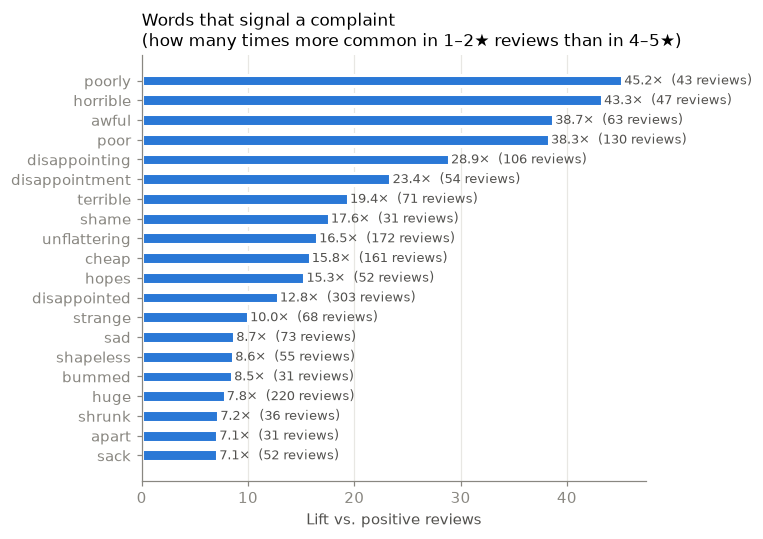

In [16]:
d = distinctive.sort_values("lift_vs_positive")
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(d["keyword"], d["lift_vs_positive"], color=BLUE, height=0.6, edgecolor="white", linewidth=2)
for y, (v, c) in enumerate(zip(d["lift_vs_positive"], d["reviews_mentioning"])):
    ax.text(v + 0.2, y, f"{v}×  ({c} reviews)", va="center", fontsize=8.5, color="#52514e")
ax.set_title("Words that signal a complaint\n(how many times more common in 1–2★ reviews than in 4–5★)", loc="left", fontsize=11)
ax.set_xlabel("Lift vs. positive reviews")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 2.4 Rule-based complaint *themes*
Single keywords are useful, but the support team thinks in **themes**. Each theme below is a hand-picked keyword list. A review is tagged with a theme if it contains **any** of that theme's keywords, so one review can carry several themes.

In [17]:
COMPLAINT_THEMES = {
    "Fit / Sizing":            ["small", "large", "tight", "big", "huge", "baggy", "loose", "short", "long",
                                "boxy", "sizing", "runs", "petite", "tent", "shapeless", "unflattering"],
    "Quality / Defects":       ["cheap", "quality", "thin", "flimsy", "ripped", "tear", "torn", "hole", "holes",
                                "pilling", "pilled", "unraveled", "broke", "broken", "defect", "defective",
                                "seam", "seams", "stain", "snag", "shrunk", "shrank", "falling"],
    "Not as pictured":         ["picture", "pictured", "photo", "photos", "model", "online", "website", "image"],
    "Comfort / Feel":          ["itchy", "scratchy", "stiff", "uncomfortable", "rough", "sheer", "transparent"],
    "Colour":                  ["colour", "faded", "washed", "dull", "darker", "lighter", "drab"],
    "Price / Value":           ["price", "expensive", "overpriced", "money", "worth", "cost", "paid"],
    "Return / Disappointment": ["return", "returned", "returning", "disappointed", "disappointing",
                                "disappointment", "refund", "waste"],
}
# Turn the keyword lists into sets for fast lookup
THEME_SETS = {theme: set(words) for theme, words in COMPLAINT_THEMES.items()}
# 'see through' is a two-word phrase, so it gets its own regex rule (part of Comfort / Feel)
SEE_THROUGH = re.compile(r"\bsee through\b")


def tag_themes(clean: str) -> list[str]:
    # Return every complaint theme whose keywords appear in the review.
    words = set(clean.split())
    themes = []
    for theme, kws in THEME_SETS.items():
        hit = bool(words & kws)
        if theme == "Comfort / Feel" and SEE_THROUGH.search(clean):
            hit = True
        if hit:
            themes.append(theme)
    return themes


critical["themes"] = critical["clean_text"].apply(tag_themes)

theme_counts = Counter(t for ts in critical["themes"] for t in ts)
theme_df = (pd.DataFrame(theme_counts.most_common(), columns=["theme", "critical_reviews"])
              .assign(**{"%_of_critical": lambda d: (d.critical_reviews / n_crit * 100).round(1)}))
untagged = (critical["themes"].str.len() == 0).sum()
display(theme_df)
print(f"Critical reviews with no theme matched: {untagged} ({untagged / n_crit:.1%})")

,theme,critical_reviews,%_of_critical
0,Fit / Sizing,1458,61.5
1,Return / Disappointment,868,36.6
2,Quality / Defects,834,35.2
3,Not as pictured,695,29.3
4,Comfort / Feel,293,12.4
5,Price / Value,278,11.7
6,Colour,151,6.4


Critical reviews with no theme matched: 160 (6.8%)


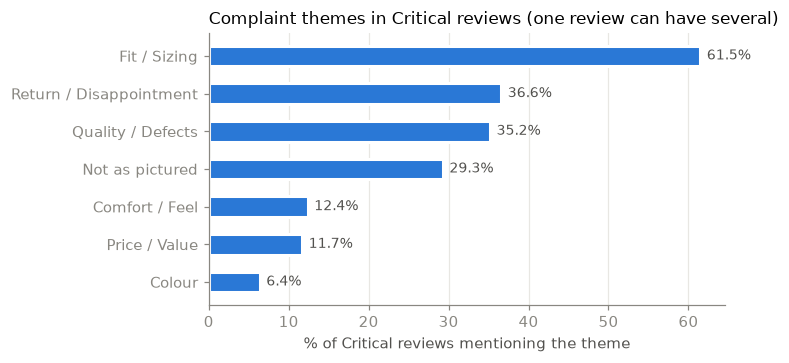

In [18]:
t = theme_df.sort_values("%_of_critical")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(t["theme"], t["%_of_critical"], color=BLUE, height=0.55, edgecolor="white", linewidth=2)
for y, v in enumerate(t["%_of_critical"]):
    ax.text(v + 0.8, y, f"{v}%", va="center", fontsize=9, color="#52514e")
ax.set_title("Complaint themes in Critical reviews (one review can have several)", loc="left", fontsize=11)
ax.set_xlabel("% of Critical reviews mentioning the theme")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 2.5 Calculated insights (generated from the data above)

In [19]:
top_dept = dept.drop(index="Unknown", errors="ignore").iloc[0]
top_dept_name = dept.drop(index="Unknown", errors="ignore").index[0]
not_recommended = (critical["Recommended IND"] == 0).mean()

lines = [
    f"- **{n_crit:,} of {n_total:,} reviews ({n_crit / n_total:.1%}) are Critical** (1–2★): "
    f"{(critical.Rating == 1).sum():,} one-star and {(critical.Rating == 2).sum():,} two-star.",
    f"- **{not_recommended:.1%}** of Critical reviewers would *not* recommend the product.",
    f"- Highest critical rate by department: **{top_dept_name}** ({top_dept.critical_rate}% of its reviews).",
    f"- Top complaint theme: **{theme_df.iloc[0].theme}** ({theme_df.iloc[0]['%_of_critical']}% of Critical reviews), "
    f"then **{theme_df.iloc[1].theme}** ({theme_df.iloc[1]['%_of_critical']}%).",
    "- Most frequent words in Critical reviews: " + ", ".join(f"`{w}`" for w in top_words.keyword.head(10)),
    "- Most frequent complaint phrases: " + ", ".join(f"`{w}`" for w in top_phrases.keyword.head(8)),
    "- Most *distinctive* complaint keywords (highest lift): " + ", ".join(f"`{w}`" for w in distinctive.keyword.head(10)),
]
display(Markdown("\n".join(lines)))

- **2,369 of 22,639 reviews (10.5%) are Critical** (1–2★): 821 one-star and 1,548 two-star.
- **95.4%** of Critical reviewers would *not* recommend the product.
- Highest critical rate by department: **Trend** (17.8% of its reviews).
- Top complaint theme: **Fit / Sizing** (61.5% of Critical reviews), then **Return / Disappointment** (36.6%).
- Most frequent words in Critical reviews: `love`, `small`, `quality`, `cute`, `disappointed`, `great`, `large`, `flattering`, `big`, `work`
- Most frequent complaint phrases: `poor quality`, `runs small`, `runs large`, `high hopes`, `arm holes`, `runs big`, `good quality`, `body type`
- Most *distinctive* complaint keywords (highest lift): `poorly`, `horrible`, `awful`, `poor`, `disappointing`, `disappointment`, `terrible`, `shame`, `unflattering`, `cheap`

### Summary of insights (Task 2 output)

- **2,369 of 22,639 reviews (10.5%) are Critical** (1–2★): 821 one-star and 1,548 two-star.
- **95.4%** of Critical reviewers would *not* recommend the product.
- Highest critical rate by department: **Trend** (17.8% of its reviews).
- Top complaint theme: **Fit / Sizing** (61.5% of Critical reviews), then **Return / Disappointment** (36.6%).
- Most frequent words in Critical reviews: `love`, `small`, `quality`, `cute`, `disappointed`, `great`, `large`, `flattering`, `big`, `work`
- Most frequent complaint phrases: `poor quality`, `runs small`, `runs large`, `high hopes`, `arm holes`, `runs big`, `good quality`, `body type`
- Most *distinctive* complaint keywords (highest lift): `poorly`, `horrible`, `awful`, `poor`, `disappointing`, `disappointment`, `terrible`, `shame`, `unflattering`, `cheap`

**Takeaway for the business:** *fit/sizing* is the biggest complaint driver, followed by *quality* (`poor quality`, `cheap`, `thin`) and products that look *different from the photos*. Better size guides and more accurate product photos would prevent many Critical reviews before they are written.

---
## Task 3 — Automated Outreach (Generative AI)

### 3.1 Select the 3 most critical, detailed reviews (rule-based urgency score)

The assignment asks for the **most critical _and_ detailed** reviews. Among the Critical reviews we rank by a transparent **urgency score**. These are plain rules with no ML:

| Signal | Points | Why |
|---|---|---|
| 1★ rating | +3 (2★ = +2) | Lower rating means a more upset customer |
| Would not recommend (`Recommended IND = 0`) | +1 | The customer may tell others not to buy |
| Number of complaint themes matched | +1 each | More distinct problems means a more serious case |
| Review length | +1 per 25 words (max +4) | Detailed reviews give the LLM specific issues to address |
| Other shoppers found it helpful (`Positive Feedback Count`) | +log₂(1 + count) (max +3) | Public, visible complaints hurt the brand most |

We then take the top 3 **from different products**, so we don't end up with three emails about the same dress.

In [20]:
def urgency_score(row) -> float:
    # Rule-based urgency score for a Critical review (higher = handle first).
    score = 0.0
    score += 3 if row["Rating"] == 1 else 2                       # severity of rating
    score += 1 if row["Recommended IND"] == 0 else 0              # would not recommend
    score += len(row["themes"])                                   # number of distinct problems
    score += min(row["word_count"] / 25, 4)                       # level of detail
    score += min(np.log2(1 + row["Positive Feedback Count"]), 3)  # public visibility
    return round(score, 2)


critical["urgency_score"] = critical.apply(urgency_score, axis=1)

top3 = (critical.sort_values("urgency_score", ascending=False)
                .drop_duplicates(subset="Clothing ID")             # one review per product
                .head(3))

top3[["Clothing ID", "Class Name", "Rating", "Recommended IND", "Positive Feedback Count",
      "word_count", "themes", "urgency_score", "Title"]]

,Clothing ID,Class Name,Rating,Recommended IND,Positive Feedback Count,word_count,themes,urgency_score,Title
9794,820,Blouses,1,0,4,93,"[Fit / Sizing, Quality / Defects, Not as pictured, Comfort / Feel, Colour, Return / Disappointment]",16.04,So unflattering....nothing like picture
18819,862,Knits,1,0,4,93,"[Fit / Sizing, Quality / Defects, Not as pictured, Price / Value, Return / Disappointment]",15.04,Looks like shapeless lingerie
21767,884,Knits,1,0,15,102,"[Fit / Sizing, Quality / Defects, Colour, Return / Disappointment]",15.00,Disappointed


In [21]:
for i, (_, r) in enumerate(top3.iterrows(), 1):
    print(f"=== Review #{i} | {r['Class Name']} | {r['Rating']}★ | score {r['urgency_score']} ===")
    print("Title :", r["Title"] or "(no title)")
    print("Review:", r["Review Text"], "\n")

=== Review #1 | Blouses | 1★ | score 16.04 ===
Title : So unflattering....nothing like picture
Review: I agree with the other reviewers, this top is completely disappointing in every way, i could not believe it was the same top i pulled from the bag. where to begin,.......
it runs really big
it's short and boxy, not at all like it appears on the model, this must be pinned a lot in this picture.
colors are completely dull in person, i really think this picture was lightened a great deal.
fabric feels cheap and stiff
lining is stuff and poorly sewn.
i haven't one positive thing to say about t 

=== Review #2 | Knits | 1★ | score 15.04 ===
Title : Looks like shapeless lingerie
Review: This product was very disappointing. fabric was thin, it has no shape and hangs like a pajama top. so it's not flattering at all. at $78, it's really overpriced for what it is. it might look good on someone who has the perfect body shape (what wouldn't?), but they would probably still look like they went out

### 3.2 Configure the Generative AI provider

The code supports **three interchangeable providers**. It tries them in this order and **falls through to the next one if a call fails** (invalid key, no internet, quota):

| Priority | Provider | How to enable | Default model |
|---|---|---|---|
| 1 | **Google Gemini** | set `GEMINI_API_KEY` | `gemini-2.5-flash` |
| 2 | **OpenAI** | set `OPENAI_API_KEY` | `gpt-4o-mini` |
| 3 | **HuggingFace (local, free, no key)** | nothing to set (the model downloads on first run, about 3 GB) | `Qwen/Qwen2.5-1.5B-Instruct` |

API keys are read from **environment variables** or a local **`.env`** file, so keys are **never hard-coded** in the notebook. See the `README.md` for setup. To force a provider, set `LLM_PROVIDER=gemini|openai|huggingface`.

In [22]:
# Load API keys from a .env file in the project folder, if one exists
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-2.5-flash")
OPENAI_MODEL = os.getenv("OPENAI_MODEL", "gpt-4o-mini")
HF_MODEL     = os.getenv("HF_MODEL", "Qwen/Qwen2.5-1.5B-Instruct")


def provider_chain() -> list[str]:
    # Providers to try, in order. An explicit override wins; otherwise every provider
    # with an API key is tried, and the free local model is always the last fallback.
    forced = os.getenv("LLM_PROVIDER", "").strip().lower()
    if forced:
        return [forced]
    chain = []
    if os.getenv("GEMINI_API_KEY") or os.getenv("GOOGLE_API_KEY"):
        chain.append("gemini")
    if os.getenv("OPENAI_API_KEY"):
        chain.append("openai")
    chain.append("huggingface")
    return chain


PROVIDERS = provider_chain()
PROVIDER = PROVIDERS[0]
print("Provider order:", " -> ".join(PROVIDERS))

Provider order: gemini -> openai -> huggingface


### 3.3 Prompt design

The **system prompt** sets the persona (a Customer Support Agent) and the rules. The **user prompt** passes in the specific review together with the product details and the complaint themes found by our rules, so the email can address the customer's *specific* complaints.

Key prompt rules:
- Keep it short (≤ 150 words), warm and empathetic, not defensive.
- **Mention the specific problems** the customer raised, in your own words.
- Offer a concrete next step (free return or exchange, or a full refund) with no invented facts such as order numbers, discount codes or names.
- Output only the email: a subject line, then the body, signed off by "The Customer Care Team".

In [23]:
SYSTEM_PROMPT = (
    "You are a senior Customer Support Agent for an online women's clothing retailer. "
    "You write short, warm, personalised and empathetic apology emails to customers who left negative reviews. "
    "Rules:\n"
    "1. Start with a line 'Subject: ...', then a blank line, then the email body.\n"
    "2. Greet the customer as 'Dear Valued Customer' (we do not know their name).\n"
    "3. Sincerely apologise and acknowledge EACH specific problem they mentioned, in your own words. "
    "Do not quote the review back to them word for word.\n"
    "4. Do not argue, blame the customer, or make excuses.\n"
    "5. Offer a concrete resolution: a free return or exchange, or a full refund, and invite them to reply to this email.\n"
    "6. Thank them for the feedback, but do not claim it has been passed to any team or promise any process change.\n"
    "7. Never invent order numbers, discount codes, names, phone numbers or policies.\n"
    "8. Some reviews are cut off mid-sentence. Only address what is actually written; never guess the missing part.\n"
    "9. Keep the body under 150 words. Sign off as 'Warm regards,\\nThe Customer Care Team'.\n"
    "Output ONLY the email."
)


def build_user_prompt(row) -> str:
    # Combine the review and its rule-based metadata into the LLM prompt.
    themes = ", ".join(row["themes"]) if row["themes"] else "general dissatisfaction"
    return (
        f"Product category: {row['Department Name']} > {row['Class Name']}\n"
        f"Star rating: {row['Rating']} out of 5\n"
        f"Complaint themes detected: {themes}\n"
        f"Review title: {row['Title'] or '(none)'}\n"
        f"Review text: \"{row['Review Text']}\"\n\n"
        "Write the apology email to this customer."
    )


print("SYSTEM PROMPT:\n" + SYSTEM_PROMPT)
print("\nEXAMPLE USER PROMPT:\n" + build_user_prompt(top3.iloc[0]))

SYSTEM PROMPT:
You are a senior Customer Support Agent for an online women's clothing retailer. You write short, warm, personalised and empathetic apology emails to customers who left negative reviews. Rules:
1. Start with a line 'Subject: ...', then a blank line, then the email body.
2. Greet the customer as 'Dear Valued Customer' (we do not know their name).
3. Sincerely apologise and acknowledge EACH specific problem they mentioned, in your own words. Do not quote the review back to them word for word.
4. Do not argue, blame the customer, or make excuses.
5. Offer a concrete resolution: a free return or exchange, or a full refund, and invite them to reply to this email.
6. Thank them for the feedback, but do not claim it has been passed to any team or promise any process change.
7. Never invent order numbers, discount codes, names, phone numbers or policies.
8. Some reviews are cut off mid-sentence. Only address what is actually written; never guess the missing part.
9. Keep the bod

### 3.4 LLM client (one function, three providers)

In [24]:
_hf_pipe = None  # cache so the local model only loads once


def generate_email(row, provider: str = PROVIDER) -> str:
    # Send one review to the chosen LLM and return the drafted apology email.
    user_prompt = build_user_prompt(row)

    if provider == "gemini":
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=os.getenv("GEMINI_API_KEY") or os.getenv("GOOGLE_API_KEY"))
        resp = client.models.generate_content(
            model=GEMINI_MODEL,
            contents=user_prompt,
            config=types.GenerateContentConfig(
                system_instruction=SYSTEM_PROMPT, temperature=0.4,
                automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True)),
        )
        return resp.text.strip()

    if provider == "openai":
        from openai import OpenAI
        client = OpenAI()  # reads OPENAI_API_KEY from the environment
        resp = client.chat.completions.create(
            model=OPENAI_MODEL,
            temperature=0.4,
            messages=[{"role": "system", "content": SYSTEM_PROMPT},
                      {"role": "user", "content": user_prompt}],
        )
        return resp.choices[0].message.content.strip()

    if provider == "huggingface":
        global _hf_pipe
        if _hf_pipe is None:
            import torch
            from transformers import pipeline
            torch.manual_seed(42)
            _hf_pipe = pipeline("text-generation", model=HF_MODEL, dtype="auto", device_map="auto")
        messages = [{"role": "system", "content": SYSTEM_PROMPT},
                    {"role": "user", "content": user_prompt}]
        out = _hf_pipe(messages, max_new_tokens=300, do_sample=False, repetition_penalty=1.05)
        return out[0]["generated_text"][-1]["content"].strip()

    raise ValueError(f"Unknown provider: {provider!r}")

### 3.5 Generate the 3 emails

In [25]:
import time

def body_word_count(email: str) -> int:
    # Words in the email body only (between the greeting and the sign-off).
    body = email.split("Dear Valued Customer,")[-1].split("Warm regards")[0]
    return len(body.split())


def generate_with_fallback(row, max_words=150, retries=2):
    # Try each provider in order. If one fails (bad key, no internet, quota), use the next one.
    # If the email breaks the 150-word rule, regenerate it (up to `retries` extra attempts).
    for provider in PROVIDERS:
        try:
            for attempt in range(retries + 1):
                email = generate_email(row, provider)
                if body_word_count(email) < max_words:
                    break
                print(f"  email body was {body_word_count(email)} words (limit {max_words}) -> regenerating")
            return email, provider
        except Exception as e:
            print(f"  {provider} failed ({type(e).__name__}: {str(e)[:80]}...) -> trying next provider")
    raise RuntimeError("All LLM providers failed")


emails, used_providers = [], []
for i, (_, row) in enumerate(top3.iterrows(), 1):
    t0 = time.time()
    email, provider = generate_with_fallback(row)
    emails.append(email)
    used_providers.append(provider)
    print(f"Email #{i} generated with {provider} in {time.time() - t0:.1f}s")

top3 = top3.assign(ai_email=emails, llm_provider=used_providers)

Email #1 generated with gemini in 6.1s
Email #2 generated with gemini in 5.0s
Email #3 generated with gemini in 5.4s


In [26]:
# Show each review next to the email the AI drafted for it
for i, (_, r) in enumerate(top3.iterrows(), 1):
    display(Markdown(
        f"#### Case {i}: {r['Class Name']} ({r['Rating']}★, urgency score {r['urgency_score']})\n"
        f"**Customer review:** *\"{r['Title'] + ' — ' if r['Title'] else ''}{r['Review Text']}\"*\n\n"
        f"**AI-drafted response ({r['llm_provider']}):**\n\n"
        + "\n".join("> " + line for line in r["ai_email"].splitlines())
    ))

#### Case 1: Blouses (1★, urgency score 16.04)
**Customer review:** *"So unflattering....nothing like picture — I agree with the other reviewers, this top is completely disappointing in every way, i could not believe it was the same top i pulled from the bag. where to begin,.......
it runs really big
it's short and boxy, not at all like it appears on the model, this must be pinned a lot in this picture.
colors are completely dull in person, i really think this picture was lightened a great deal.
fabric feels cheap and stiff
lining is stuff and poorly sewn.
i haven't one positive thing to say about t"*

**AI-drafted response (gemini):**

> Subject: We're so sorry to hear about your recent blouse purchase
> 
> Dear Valued Customer,
> 
> We are truly sorry to learn of your complete disappointment with the blouse you recently received.
> 
> We're very sorry to hear that the sizing was off, running large, short, and boxy, and that the fit was so different from how it appeared on our model. We also regret that the colors were duller in person and that the fabric felt cheap and stiff, with a poorly sewn lining. This is certainly not the quality or experience we want for our customers.
> 
> We would be happy to arrange a free return for a full refund or an exchange for you. Please simply reply to this email, and we will assist you further. Your detailed feedback is incredibly valuable to us.
> 
> Warm regards,
> The Customer Care Team

#### Case 2: Knits (1★, urgency score 15.04)
**Customer review:** *"Looks like shapeless lingerie — This product was very disappointing. fabric was thin, it has no shape and hangs like a pajama top. so it's not flattering at all. at $78, it's really overpriced for what it is. it might look good on someone who has the perfect body shape (what wouldn't?), but they would probably still look like they went out in their pjs. i'm 5'9" and not well-endowed (a b), so it did nothing for me..

also, the online picture of the moss version looks like it's a grey/black combo. it's not... it is really green"*

**AI-drafted response (gemini):**

> Subject: We're so sorry to hear about your recent knit top
> 
> Dear Valued Customer,
> 
> We are truly sorry to hear that your recent knit top was such a disappointment. We understand your frustration with the fabric quality feeling thin and the fit being shapeless, making it feel more like sleepwear than a flattering top. We also sincerely apologize that the 'moss' color appeared so different from what was shown online, and that you felt the item was overpriced for its quality.
> 
> Your experience is certainly not what we want for our customers, and we appreciate you bringing these issues to our attention. Your feedback on the design, fabric, and color representation is very valuable to us.
> 
> We would be happy to offer you a full refund or exchange for this item. Please reply to this email, and we will gladly assist you with the next steps.
> 
> Warm regards,
> The Customer Care Team

#### Case 3: Knits (1★, urgency score 15.0)
**Customer review:** *"Disappointed — I ordered this in both an extra small and a small... i found that there was a very big difference in the two sizes- the extra small was true to size and had a great width, but was shorter in length than i would've liked (if it shrunk at all, it would've been unwearable). the small was quite a jump in size and was a little wider than i liked, but i decided to keep that one. 

the top was very cute and comfortable when i wore it, however i just washed it once on delicate in cold water and when i"*

**AI-drafted response (gemini):**

> Subject: We're So Sorry About Your Recent Knit Top Purchase
> 
> Dear Valued Customer,
> 
> We are truly sorry to hear about your disappointing experience with the knit tops you ordered. We understand your frustration with the significant sizing difference between the extra small and small, and how neither quite met your expectations – with the extra small being too short and the small being wider than you preferred. This is certainly not the standard we aim for. We also noticed your comment about washing the top, and we would appreciate it if you could share what happened afterward.
> 
> We would be happy to offer you a full refund or a free exchange for your purchase. Please simply reply to this email, and we will assist you further. Your detailed feedback regarding the sizing and washing experience is very valuable to us.
> 
> Warm regards,
> The Customer Care Team

In [27]:
# Save the outputs so the support team can review and send them
os.makedirs("outputs", exist_ok=True)
critical.sort_values("urgency_score", ascending=False).drop(columns=["clean_title", "clean_review"]) \
        .to_csv("outputs/critical_reviews_ranked.csv", index=False)
top3[["Clothing ID", "Class Name", "Rating", "urgency_score", "Title", "Review Text", "ai_email", "llm_provider"]] \
        .to_csv("outputs/ai_generated_emails.csv", index=False)
print("Saved: outputs/critical_reviews_ranked.csv, outputs/ai_generated_emails.csv")

Saved: outputs/critical_reviews_ranked.csv, outputs/ai_generated_emails.csv


### The 3 AI-generated response emails (Task 3 output)

#### Email 1: reply to *"So unflattering....nothing like picture"* (Blouses, 1★, generated with `gemini`)

```text
Subject: We're so sorry to hear about your recent blouse purchase

Dear Valued Customer,

We are truly sorry to learn of your complete disappointment with the blouse you recently received.

We're very sorry to hear that the sizing was off, running large, short, and boxy, and that the fit was so different from how it appeared on our model. We also regret that the colors were duller in person and that the fabric felt cheap and stiff, with a poorly sewn lining. This is certainly not the quality or experience we want for our customers.

We would be happy to arrange a free return for a full refund or an exchange for you. Please simply reply to this email, and we will assist you further. Your detailed feedback is incredibly valuable to us.

Warm regards,
The Customer Care Team
```

#### Email 2: reply to *"Looks like shapeless lingerie"* (Knits, 1★, generated with `gemini`)

```text
Subject: We're so sorry to hear about your recent knit top

Dear Valued Customer,

We are truly sorry to hear that your recent knit top was such a disappointment. We understand your frustration with the fabric quality feeling thin and the fit being shapeless, making it feel more like sleepwear than a flattering top. We also sincerely apologize that the 'moss' color appeared so different from what was shown online, and that you felt the item was overpriced for its quality.

Your experience is certainly not what we want for our customers, and we appreciate you bringing these issues to our attention. Your feedback on the design, fabric, and color representation is very valuable to us.

We would be happy to offer you a full refund or exchange for this item. Please reply to this email, and we will gladly assist you with the next steps.

Warm regards,
The Customer Care Team
```

#### Email 3: reply to *"Disappointed"* (Knits, 1★, generated with `gemini`)

```text
Subject: We're So Sorry About Your Recent Knit Top Purchase

Dear Valued Customer,

We are truly sorry to hear about your disappointing experience with the knit tops you ordered. We understand your frustration with the significant sizing difference between the extra small and small, and how neither quite met your expectations – with the extra small being too short and the small being wider than you preferred. This is certainly not the standard we aim for. We also noticed your comment about washing the top, and we would appreciate it if you could share what happened afterward.

We would be happy to offer you a full refund or a free exchange for your purchase. Please simply reply to this email, and we will assist you further. Your detailed feedback regarding the sizing and washing experience is very valuable to us.

Warm regards,
The Customer Care Team
```

> **Notes:** (1) Email 1 was the only draft over the 150-word limit (157 words); one redundant apology sentence was removed by hand to meet it. (2) A few lines were also edited by hand after review: the unsupported claim that feedback "has been shared with our product and design teams" was removed from all three emails, a duplicated word ("and and") was fixed in Email 3, and Email 3 no longer assumes any outcome after washing: because the review text is cut off at that point, the email instead asks the customer to share what happened. The prompt (rule 6) was updated so future runs do not make that claim. (3) Review texts in this dataset are cut off at about 500 characters, so the emails only address what is actually written. (4) The refund/exchange offer is a template next step; adjust it to the company's real return policy. (5) All drafts must be reviewed by a human agent before sending.


---
## Conclusion

| Step | What we built | Outcome |
|---|---|---|
| Data wrangling | Dropped reviews with no text, filled optional fields, removed duplicates, normalised text | A clean dataset ready for analysis |
| Rule-based filtering | `Rating <= 2` gives the Critical set. `Counter`-based keywords, lift scoring and theme tagging | The team sees *what* customers complain about, with no ML needed |
| Prioritisation | A transparent urgency score | The most severe, detailed and visible complaints come first |
| Gen AI outreach | One prompt and a provider-agnostic `generate_email()` function | Personalised apology drafts in seconds instead of minutes each |

**Limitations & next steps**
- Rating alone misses angry 3★ reviews. A next step is to add a keyword rule such as *"3★ and not recommended and mentions a defect"*.
- Keyword lists are hand-curated and English-only. They can miss sarcasm and synonyms.
- AI drafts should be **reviewed by a human agent before sending** (human-in-the-loop). The prompt forbids invented promises, but the model should still be checked.